# Etapa 1 — Melhor cenário de candle × janela de treino (Random Forest)

**Objetivo:** escolher o tamanho de candle e o tempo de treinamento para prever o retorno do próximo candle do WIN (T+1).

| Item | Definição |
|---|---|
| Alvo | $r_{t+1} = 100 \cdot \ln(C_{t+1} / C_t)$, só dentro do mesmo pregão |
| Candles | 1, 5, 15 e 60 min |
| Janelas de treino | 3, 6, 12 e 24 meses |
| Modelo | Random Forest **fixo e simples** (os hiperparâmetros são da etapa 3) |
| Features | **básicas** (as melhores features são da etapa 2): 3 últimos retornos, volatilidade móvel, hora |
| Período de seleção | 2024, re-treinando a cada trimestre com a janela imediatamente anterior |
| Não usado aqui | 01/2025 → 03/2026 (validação final, rodada uma vez com o modelo congelado) |

**Painel de métricas**

| Métrica | Papel |
|---|---|
| Theil U = RMSE(modelo) / RMSE(prever zero) | filtro: elimina cenários com U ≥ 1 em mais da metade dos trimestres |
| Correlação de Spearman (previsão × real) | critério principal |
| Estatística t da correlação ($\rho\sqrt{n}$) | corrige o tamanho da amostra (1 min tem ~60× mais candles que 60 min) |
| Acerto de direção | complementar |
| Estabilidade (desvio da correlação entre trimestres) | desempate |
| Esperança indicativa (pts/op, custo de 5 pts, opera o sinal de $\hat r$ em todo candle) | só referência; a regra real é da etapa 4 |

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

PASTA = Path.cwd() if (Path.cwd() / "WIN$N_M1.csv").exists() else Path.cwd().parent
ARQ_WIN = PASTA / "WIN$N_M1.csv"
PASTA_RES = PASTA / "resultados"
PASTA_RES.mkdir(exist_ok=True)

CANDLES = [1, 5, 15, 60]          # minutos
JANELAS = [3, 6, 12, 24]          # meses de treino
TRIMESTRES_2024 = pd.period_range("2024Q1", "2024Q4", freq="Q")
CUSTO_PTS = 5.0                   # custo por operação completa (pontos)
SEED = 42

# Random Forest fixo e regularizado (sinal fraco -> árvores rasas e folhas grandes)
RF_PARAMS = dict(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=0.01,   # 1% do treino em cada folha
    max_features=1.0,
    max_samples=0.5,         # cada árvore vê metade do treino (mais rápido e menos correlacionado)
    n_jobs=-1,
    random_state=SEED,
)
FEATURES = ["ret_0", "ret_1", "ret_2", "vol_20", "hora"]

## 1. Carregar os candles de 1 minuto

In [2]:
m1 = pd.read_csv(ARQ_WIN, sep="\t")
m1.columns = [c.strip("<>").lower() for c in m1.columns]
m1["dt"] = pd.to_datetime(m1["date"] + " " + m1["time"], format="%Y.%m.%d %H:%M:%S")
m1 = (m1.drop(columns=["date", "time", "spread"])
        .set_index("dt").sort_index())
m1 = m1[~m1.index.duplicated()]

# Só o pregão regular (9:00 a 18:24); descarta registros de leilão/after
m1 = m1.between_time("09:00", "18:24")
print(f"{len(m1):,} candles de 1 min · {m1.index.min()} -> {m1.index.max()}")
print(f"{m1.index.normalize().nunique()} pregões")

757,711 candles de 1 min · 2020-10-15 11:49:00 -> 2026-09-25 18:24:00
1368 pregões


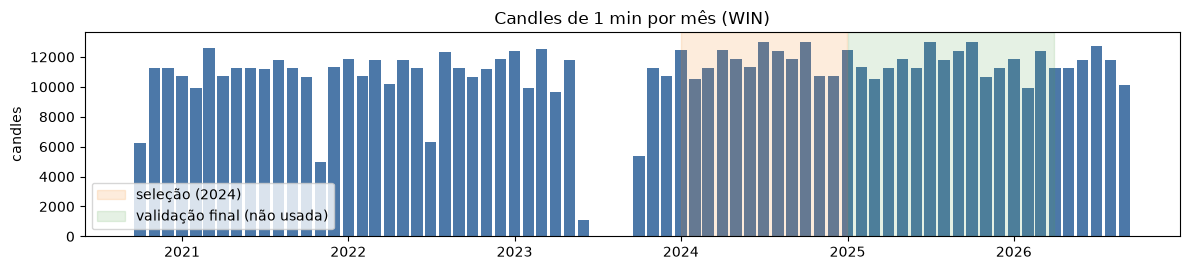

Meses com menos de 8.000 candles:
dt
2020-10    6246
2021-11    4960
2022-07    6295
2023-06    1070
2023-10    5408
Freq: M


In [3]:
# Cobertura mensal: mostra os buracos da base (o maior entre jun e out/2023)
cob = m1.groupby(m1.index.to_period("M")).size()
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.bar(cob.index.to_timestamp(), cob.values, width=25, color="#4C78A8")
ax.set_title("Candles de 1 min por mês (WIN)")
ax.set_ylabel("candles")
ax.axvspan(pd.Timestamp("2024-01-01"), pd.Timestamp("2024-12-31"), color="#F58518", alpha=0.15, label="seleção (2024)")
ax.axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2026-03-31"), color="#54A24B", alpha=0.15, label="validação final (não usada)")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

print("Meses com menos de 8.000 candles:")
print(cob[cob < 8000].to_string())

## 2. Agregar em candles maiores e montar alvo e features

- Cada candle de *k* minutos é formado **dentro do pregão**, alinhado ao relógio (9:00, 9:05, ...).
- **Alvo:** retorno do próximo candle do mesmo pregão. O último candle do dia não tem alvo, porque o par atravessaria a noite.
- **Features (só informação até t):**
  - `ret_0`, `ret_1`, `ret_2`: retornos intradiários do candle atual e dos dois anteriores. Nos primeiros candles do dia valem 0, para não usar o gap de abertura.
  - `vol_20`: desvio-padrão dos últimos 20 retornos intradiários.
  - `hora`: horário do candle em horas decimais.
- **Pontos:** $C_{t+1} - C_t$, usado na esperança indicativa.

In [4]:
def agrega_candles(m1: pd.DataFrame, minutos: int) -> pd.DataFrame:
    if minutos == 1:
        return m1.copy()
    regras = {"open": "first", "high": "max", "low": "min", "close": "last",
              "tickvol": "sum", "vol": "sum"}
    out = m1.resample(f"{minutos}min", label="left", closed="left").agg(regras)
    return out.dropna(subset=["close"])


def monta_base(m1: pd.DataFrame, minutos: int) -> pd.DataFrame:
    df = agrega_candles(m1, minutos)
    dia = df.index.normalize()
    lc = np.log(df["close"])

    # retorno intradiário do candle t (NaN no primeiro candle do dia)
    ret = 100 * lc.groupby(dia).diff()

    df["ret_0"] = ret
    df["ret_1"] = ret.groupby(dia).shift(1)
    df["ret_2"] = ret.groupby(dia).shift(2)
    df["vol_20"] = ret.rolling(20, min_periods=10).std()
    df["hora"] = df.index.hour + df.index.minute / 60

    # alvo: retorno do próximo candle no MESMO pregão
    df["alvo"] = ret.groupby(dia).shift(-1)
    df["pts_prox"] = df["close"].groupby(dia).shift(-1) - df["close"]

    df[["ret_0", "ret_1", "ret_2"]] = df[["ret_0", "ret_1", "ret_2"]].fillna(0.0)
    return df.dropna(subset=["alvo", "vol_20"])


bases = {}
for k in CANDLES:
    bases[k] = monta_base(m1, k)
    b = bases[k]
    print(f"{k:>3} min: {len(b):>8,} linhas · desvio do alvo = {b['alvo'].std():.4f}% · "
          f"{b.index.min().date()} -> {b.index.max().date()}")

  1 min:  756,333 linhas · desvio do alvo = 0.0459% · 2020-10-15 -> 2026-09-25


  5 min:  150,285 linhas · desvio do alvo = 0.1000% · 2020-10-15 -> 2026-09-25


 15 min:   49,642 linhas · desvio do alvo = 0.1712% · 2020-10-15 -> 2026-09-25


 60 min:   11,865 linhas · desvio do alvo = 0.3348% · 2020-10-16 -> 2026-09-25


In [5]:
# Conferência rápida: amostra da base de 15 min
bases[15][FEATURES + ["alvo", "pts_prox"]].head(8)

,ret_0,ret_1,ret_2,vol_20,hora,alvo,pts_prox
dt,,,,,,,
2020-10-15 14:15:00,0.277505,0.060649,0.161911,0.135611,14.25,0.251610,250.0
2020-10-15 14:30:00,0.251610,0.277505,0.060649,0.141389,14.50,-0.135791,-135.0
2020-10-15 14:45:00,-0.135791,0.251610,0.277505,0.147880,14.75,0.281436,280.0
2020-10-15 15:00:00,0.281436,-0.135791,0.251610,0.154638,15.00,-0.185860,-185.0
2020-10-15 15:15:00,-0.185860,0.281436,-0.135791,0.164057,15.25,-0.060353,-60.0
2020-10-15 15:30:00,-0.060353,-0.185860,0.281436,0.160913,15.50,0.085489,85.0
2020-10-15 15:45:00,0.085489,-0.060353,-0.185860,0.155737,15.75,-0.035193,-35.0
2020-10-15 16:00:00,-0.035193,0.085489,-0.060353,0.152216,16.00,-0.085520,-85.0


## 3. Avaliação walk-forward em 2024

Para cada cenário (candle × janela) e cada trimestre de 2024:

1. Treinar o RF com os candles de **[início do trimestre − janela, início do trimestre)**.
2. Prever todos os candles do trimestre.
3. Guardar as previsões e calcular as métricas por trimestre e no ano inteiro (2024 empilhado).

O buraco de jul a set/2023 reduz o treino real das janelas que pegam esse período. Por isso, `n_treino` é registrado em cada ajuste.

In [6]:
def theil_u(y, p):
    return np.sqrt(np.sum((y - p) ** 2) / np.sum(y ** 2))


def metricas(y, p, pts):
    y, p, pts = np.asarray(y), np.asarray(p), np.asarray(pts)
    n = len(y)
    rho = spearmanr(p, y).statistic if np.std(p) > 0 else np.nan
    mov = y != 0
    acerto = np.mean(np.sign(p[mov]) == np.sign(y[mov]))
    # esperança indicativa: opera o sinal da previsão em todo candle
    opera = np.sign(p) != 0
    res = np.sign(p[opera]) * pts[opera] - CUSTO_PTS
    return {
        "n": n,
        "theil_u": theil_u(y, p),
        "spearman": rho,
        "t_corr": rho * np.sqrt(n) if np.isfinite(rho) else np.nan,
        "acerto_dir": acerto,
        "esperanca_pts": res.mean(),
        "ep_esperanca": res.std(ddof=1) / np.sqrt(len(res)),
    }


def avalia_cenario(base, meses):
    linhas, prevs = [], []
    for q in TRIMESTRES_2024:
        ini_teste, fim_teste = q.start_time, q.end_time
        ini_treino = ini_teste - pd.DateOffset(months=meses)
        tr = base[(base.index >= ini_treino) & (base.index < ini_teste)]
        te = base[(base.index >= ini_teste) & (base.index <= fim_teste)]

        rf = RandomForestRegressor(**RF_PARAMS)
        rf.fit(tr[FEATURES], tr["alvo"])
        p = rf.predict(te[FEATURES])

        m = metricas(te["alvo"], p, te["pts_prox"])
        m.update(trimestre=str(q), n_treino=len(tr), desvio_prev=p.std())
        linhas.append(m)
        prevs.append(pd.DataFrame({"alvo": te["alvo"], "prev": p,
                                   "pts_prox": te["pts_prox"], "trimestre": str(q)}))
    return pd.DataFrame(linhas), pd.concat(prevs)

In [7]:
por_trim, anual, previsoes = [], [], {}
t0 = time.time()
for k in CANDLES:
    for meses in JANELAS:
        t1 = time.time()
        tri, prev = avalia_cenario(bases[k], meses)
        tri.insert(0, "janela_m", meses); tri.insert(0, "candle_min", k)
        por_trim.append(tri)
        previsoes[(k, meses)] = prev

        a = metricas(prev["alvo"], prev["prev"], prev["pts_prox"])
        a.update(candle_min=k, janela_m=meses,
                 trim_u_menor_1=int((tri["theil_u"] < 1).sum()),
                 spearman_medio_trim=tri["spearman"].mean(),
                 spearman_desvio_trim=tri["spearman"].std(ddof=1),
                 n_treino_min=int(tri["n_treino"].min()))
        anual.append(a)
        print(f"{k:>3} min × {meses:>2} m  ·  U={a['theil_u']:.4f}  ρ={a['spearman']:+.4f}  "
              f"t={a['t_corr']:+.2f}  ({time.time() - t1:.0f}s)")

por_trim = pd.concat(por_trim, ignore_index=True)
anual = pd.DataFrame(anual)
print(f"\nTotal: {time.time() - t0:.0f}s")

  1 min ×  3 m  ·  U=1.0003  ρ=+0.0115  t=+4.32  (12s)


  1 min ×  6 m  ·  U=1.0002  ρ=+0.0120  t=+4.52  (21s)


  1 min × 12 m  ·  U=1.0000  ρ=+0.0163  t=+6.11  (36s)


  1 min × 24 m  ·  U=1.0000  ρ=+0.0057  t=+2.14  (89s)


  5 min ×  3 m  ·  U=1.0016  ρ=+0.0081  t=+1.37  (7s)


  5 min ×  6 m  ·  U=1.0010  ρ=+0.0136  t=+2.28  (8s)


... (6 outputs left out)

 60 min ×  3 m  ·  U=1.0296  ρ=-0.0315  t=-1.49  (5s)


 60 min ×  6 m  ·  U=1.0164  ρ=-0.0092  t=-0.44  (4s)


 60 min × 12 m  ·  U=1.0132  ρ=-0.0202  t=-0.96  (4s)


 60 min × 24 m  ·  U=1.0039  ρ=-0.0198  t=-0.94  (5s)

Total: 242s


## 4. Resultados

### 4.1 Mapas de calor: Theil U e correlação (2024 inteiro)

Se os dois mapas apontarem para a mesma região, a escolha é robusta.

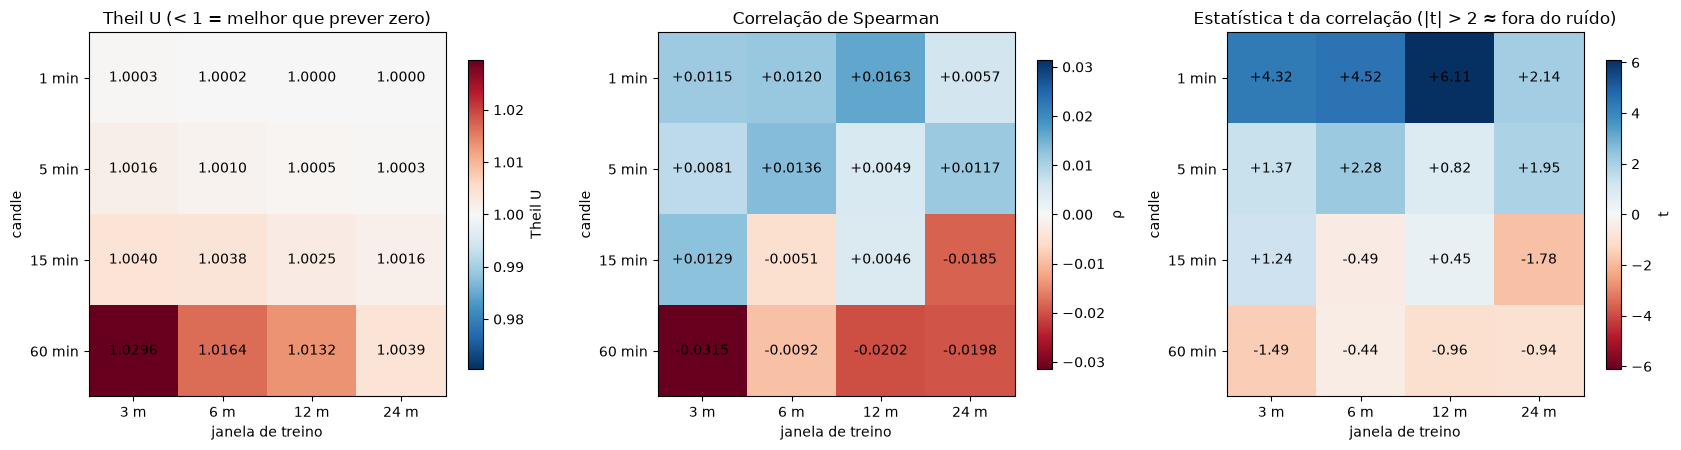

In [8]:
def mapa(ax, tabela, titulo, cmap, centro, fmt, rotulo):
    v = tabela.values
    amp = np.nanmax(np.abs(v - centro))
    im = ax.imshow(v, cmap=cmap, vmin=centro - amp, vmax=centro + amp, aspect="auto")
    ax.set_xticks(range(tabela.shape[1]), [f"{c} m" for c in tabela.columns])
    ax.set_yticks(range(tabela.shape[0]), [f"{i} min" for i in tabela.index])
    ax.set_xlabel("janela de treino"); ax.set_ylabel("candle")
    ax.set_title(titulo)
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            ax.text(j, i, format(v[i, j], fmt), ha="center", va="center", fontsize=10)
    plt.colorbar(im, ax=ax, label=rotulo, shrink=0.85)


tab_u = anual.pivot(index="candle_min", columns="janela_m", values="theil_u")
tab_r = anual.pivot(index="candle_min", columns="janela_m", values="spearman")
tab_t = anual.pivot(index="candle_min", columns="janela_m", values="t_corr")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
mapa(axes[0], tab_u, "Theil U (< 1 = melhor que prever zero)", "RdBu_r", 1.0, ".4f", "Theil U")
mapa(axes[1], tab_r, "Correlação de Spearman", "RdBu", 0.0, "+.4f", "ρ")
mapa(axes[2], tab_t, "Estatística t da correlação (|t| > 2 ≈ fora do ruído)", "RdBu", 0.0, "+.2f", "t")
plt.tight_layout(); plt.show()

### 4.2 Estabilidade entre trimestres

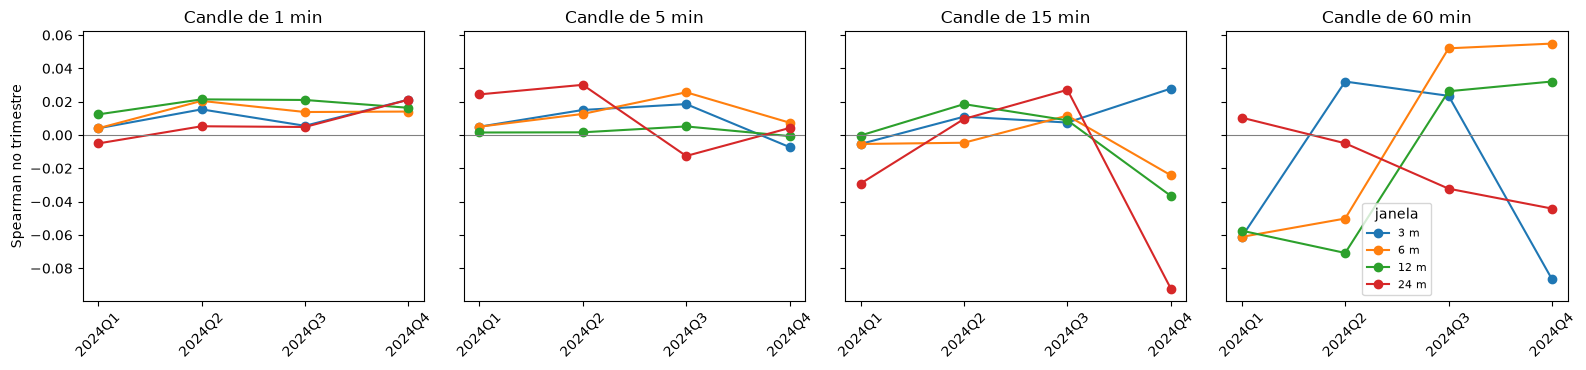

In [9]:
fig, axes = plt.subplots(1, len(CANDLES), figsize=(16, 3.8), sharey=True)
for ax, k in zip(axes, CANDLES):
    d = por_trim[por_trim["candle_min"] == k]
    for meses in JANELAS:
        s = d[d["janela_m"] == meses]
        ax.plot(s["trimestre"], s["spearman"], marker="o", label=f"{meses} m")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(f"Candle de {k} min"); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Spearman no trimestre")
axes[-1].legend(title="janela", fontsize=8)
plt.tight_layout(); plt.show()

### 4.3 Tabela completa e regra de escolha

1. **Filtro:** eliminar cenários com U ≥ 1 em mais da metade dos trimestres (fica quem tem U < 1 em pelo menos 2 de 4).
2. **Ranking:** correlação média entre trimestres.
3. **Desempate:** menor desvio da correlação entre trimestres e maior estatística t.
4. Se nenhum cenário passar no filtro, seguir com o de maior correlação e registrar que o RF não superou o naive.

In [10]:
colunas = ["candle_min", "janela_m", "n_treino_min", "n", "theil_u", "trim_u_menor_1",
           "spearman", "spearman_medio_trim", "spearman_desvio_trim", "t_corr",
           "acerto_dir", "esperanca_pts", "ep_esperanca"]
tabela = anual[colunas].copy()
tabela["passa_filtro_u"] = tabela["trim_u_menor_1"] >= 2

ranking = tabela.sort_values(
    ["passa_filtro_u", "spearman_medio_trim", "spearman_desvio_trim", "t_corr"],
    ascending=[False, False, True, False]).reset_index(drop=True)
ranking.index += 1

tabela.to_csv(PASTA_RES / "etapa1_resultados_2024.csv", index=False)
por_trim.to_csv(PASTA_RES / "etapa1_resultados_por_trimestre.csv", index=False)

ranking.style.format({
    "theil_u": "{:.4f}", "spearman": "{:+.4f}", "spearman_medio_trim": "{:+.4f}",
    "spearman_desvio_trim": "{:.4f}", "t_corr": "{:+.2f}", "acerto_dir": "{:.1%}",
    "esperanca_pts": "{:+.1f}", "ep_esperanca": "{:.1f}", "n": "{:,}", "n_treino_min": "{:,}",
}).background_gradient(subset=["spearman_medio_trim"], cmap="RdBu", vmin=-0.05, vmax=0.05)

,candle_min,janela_m,n_treino_min,n,theil_u,trim_u_menor_1,spearman,spearman_medio_trim,spearman_desvio_trim,t_corr,acerto_dir,esperanca_pts,ep_esperanca,passa_filtro_u
1,5,24,"42,758","28,063",1.0003,2,+0.0117,+0.0115,0.0195,+1.95,51.0%,-3.8,0.5,True
2,1,12,"83,902","141,302",1.0000,1,+0.0163,+0.0178,0.0043,+6.11,50.9%,-4.6,0.1,False
3,1,6,"27,320","141,302",1.0002,1,+0.0120,+0.0131,0.0068,+4.52,50.7%,-4.8,0.1,False
4,5,6,"5,428","28,063",1.0010,0,+0.0136,+0.0127,0.0092,+2.28,50.7%,-4.4,0.5,False
5,1,3,"27,320","141,302",1.0003,1,+0.0115,+0.0115,0.0082,+4.32,50.8%,-4.8,0.1,False
6,15,3,"1,793","9,271",1.0040,0,+0.0129,+0.0102,0.0137,+1.24,50.8%,-4.7,1.6,False
7,5,3,"5,428","28,063",1.0016,0,+0.0081,+0.0078,0.0116,+1.37,50.6%,-4.9,0.5,False
8,1,24,"215,290","141,302",1.0000,1,+0.0057,+0.0065,0.0109,+2.14,50.2%,-4.9,0.1,False
9,5,12,"16,663","28,063",1.0005,0,+0.0049,+0.0019,0.0024,+0.82,50.1%,-4.8,0.5,False
10,60,6,430,"2,255",1.0164,0,-0.0092,-0.0011,0.0632,-0.44,49.1%,-4.4,6.2,False


In [11]:
algum_passa = ranking["passa_filtro_u"].any()
escolhido = ranking.iloc[0]
CANDLE_ESCOLHIDO, JANELA_ESCOLHIDA = int(escolhido["candle_min"]), int(escolhido["janela_m"])

print("Algum cenário com U < 1 em pelo menos 2 trimestres?", "sim" if algum_passa else "NÃO")
print(f"\nCenário escolhido para as próximas etapas: candle de {CANDLE_ESCOLHIDO} min × janela de {JANELA_ESCOLHIDA} meses")
print(f"  Theil U 2024           = {escolhido['theil_u']:.4f}  (U < 1 em {escolhido['trim_u_menor_1']} de 4 trimestres)")
print(f"  Spearman 2024          = {escolhido['spearman']:+.4f}  (t = {escolhido['t_corr']:+.2f})")
print(f"  Spearman por trimestre = {escolhido['spearman_medio_trim']:+.4f} ± {escolhido['spearman_desvio_trim']:.4f}")
print(f"  Acerto de direção      = {escolhido['acerto_dir']:.1%}")
print(f"  Esperança indicativa   = {escolhido['esperanca_pts']:+.1f} ± {escolhido['ep_esperanca']:.1f} pts/op (custo {CUSTO_PTS:.0f} pts, todo candle)")

pd.Series({"candle_min": CANDLE_ESCOLHIDO, "janela_m": JANELA_ESCOLHIDA}).to_json(
    PASTA_RES / "etapa1_escolha.json")

Algum cenário com U < 1 em pelo menos 2 trimestres? sim

Cenário escolhido para as próximas etapas: candle de 5 min × janela de 24 meses
  Theil U 2024           = 1.0003  (U < 1 em 2 de 4 trimestres)
  Spearman 2024          = +0.0117  (t = +1.95)
  Spearman por trimestre = +0.0115 ± 0.0195
  Acerto de direção      = 51.0%
  Esperança indicativa   = -3.8 ± 0.5 pts/op (custo 5 pts, todo candle)


### 4.4 Diagnóstico do cenário escolhido

Com sinal fraco, o RF tende a **encolher** as previsões para perto de zero. Comparar o desvio da previsão com o do retorno real mostra o quanto o modelo "se arrisca". O retorno médio por decil da previsão mostra se a ordenação tem sentido econômico.

Desvio da previsão: 0.0016%  ·  desvio do retorno real: 0.0713%


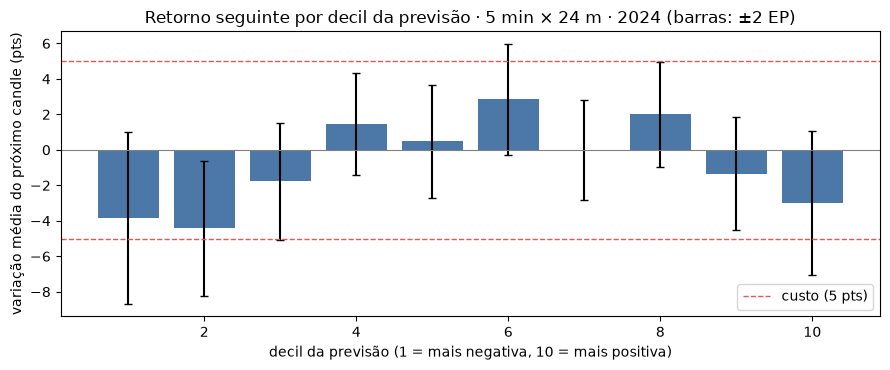

,prev_media,real_medio,pts_medio,n
decil,,,,
1,-0.003062,-0.002924,-3.824368,2807
2,-0.000882,-0.003353,-4.422666,2806
3,-0.000121,-0.001425,-1.778332,2806
4,0.000274,0.001089,1.466500,2806
5,0.000530,0.000358,0.479159,2807
6,0.000734,0.002185,2.840342,2806
7,0.000926,0.000063,-0.012473,2806
8,0.001175,0.001500,1.999287,2806
9,0.001560,-0.001066,-1.343550,2806


In [12]:
prev = previsoes[(CANDLE_ESCOLHIDO, JANELA_ESCOLHIDA)].copy()
print(f"Desvio da previsão: {prev['prev'].std():.4f}%  ·  desvio do retorno real: {prev['alvo'].std():.4f}%")

prev["decil"] = pd.qcut(prev["prev"].rank(method="first"), 10, labels=range(1, 11))
dec = prev.groupby("decil", observed=True).agg(
    prev_media=("prev", "mean"), real_medio=("alvo", "mean"),
    pts_medio=("pts_prox", "mean"), n=("alvo", "size"))
ep = prev.groupby("decil", observed=True)["pts_prox"].agg(lambda s: s.std(ddof=1) / np.sqrt(len(s)))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(dec.index.astype(int), dec["pts_medio"], yerr=2 * ep.values, color="#4C78A8", capsize=3)
ax.axhline(0, color="grey", lw=0.8)
ax.axhline(CUSTO_PTS, color="#E45756", ls="--", lw=1, label=f"custo ({CUSTO_PTS:.0f} pts)")
ax.axhline(-CUSTO_PTS, color="#E45756", ls="--", lw=1)
ax.set_xlabel("decil da previsão (1 = mais negativa, 10 = mais positiva)")
ax.set_ylabel("variação média do próximo candle (pts)")
ax.set_title(f"Retorno seguinte por decil da previsão · {CANDLE_ESCOLHIDO} min × {JANELA_ESCOLHIDA} m · 2024 (barras: ±2 EP)")
ax.legend(); plt.tight_layout(); plt.show()
dec

## 5. Conclusão da etapa 1 e próximos passos

**Fica congelado para as etapas seguintes:** o candle e a janela escolhidos acima (salvos em `resultados/etapa1_escolha.json`).

**Como ler o resultado:**
- U muito perto de 1 e correlação com |t| < 2 significam que, **com as features básicas**, o RF não separa o sinal do ruído. Isso é esperado nesta etapa e é o que a etapa 2 tenta mudar.
- A esperança indicativa opera **todo candle**, então o custo domina. Ela serve só para comparar cenários; a regra de entrada e saída é da etapa 4.

**Próximas etapas do roteiro:**
1. **Etapa 2 (features):** análise de dados de cada candidata contra o alvo (Spearman, informação mútua, retorno por decil), remoção das redundantes e confirmação por importância por permutação.
2. **Etapa 3 (hiperparâmetros):** grade pequena de `max_depth`, `min_samples_leaf` e `max_features`.
3. **Etapa 4 (regras de negócio):** limiar de entrada, take profit e stop pela volatilidade, filtro de horário.
4. **Congelar e validar** uma vez em 01/2025 → 03/2026.

**Limitações desta etapa (para os próximos passos do trabalho):**
- A escolha usa um único ano (2024). Repetir a grade em 2023 checaria se o melhor cenário se mantém.
- O candle e a janela foram escolhidos com features básicas; depois da etapa 2 vale confirmar se o ranking muda.
- A janela é contada em meses de calendário; o buraco de jul–set/2023 deixa algumas janelas com menos dados que o nominal (`n_treino_min` na tabela).